# Supplementary Figure S15a. STRING network of INO80E cis-region genes and ABCA1

STRING (v12.5, *Homo sapiens*, combined score >= 0.4) network among proteins encoded by 13 genes of the 16p11.2 INO80E cis region (MVP, TBX6, YPEL3, GDPD3, MAPK3, PPP4C, ASPHD1, KCTD13, DOC2A, SEZ6L2, TMEM219, TAOK2, INO80E) and the distal target *ABCA1* (red nodes: *INO80E* and *ABCA1*); all 14 query genes are drawn, including those without edges. Grey edges are functional associations; no pair passes the threshold in STRING's physical network, so there are no red edges. No author code or network file exists for this panel: the gene set was read from the published panel and the network was retrieved with the same STRING settings as the author's other network panels. ABCA1 and MVP have no edges at this threshold. `ppi$gene_sets` marks which genes are AD-colocalized cis-eGenes in CoS15 or were tested in panels b-c.

Input: `data/Figure_S15a_INO80E_region_ABCA1_PPI.rds`


In [1]:
library(ggplot2)
library(ggrepel)
ppi <- readRDS("data/Figure_S15a_INO80E_region_ABCA1_PPI.rds")
ppi$gene_sets
c(n_nodes = nrow(ppi$nodes), n_edges = nrow(ppi$edges))
table(ppi$edges$type)

gene,colocalized_cis_eGene_CoS15,in_bidirectional_mediation,distal_target
<chr>,<lgl>,<lgl>,<lgl>
MVP,FALSE,FALSE,FALSE
TBX6,FALSE,FALSE,FALSE
YPEL3,FALSE,TRUE,FALSE
GDPD3,FALSE,TRUE,FALSE
MAPK3,TRUE,TRUE,FALSE
PPP4C,FALSE,TRUE,FALSE
ASPHD1,TRUE,TRUE,FALSE
KCTD13,TRUE,TRUE,FALSE
DOC2A,TRUE,TRUE,FALSE


n_nodes n_edges 
     14      55


Functional association only 
                         55 

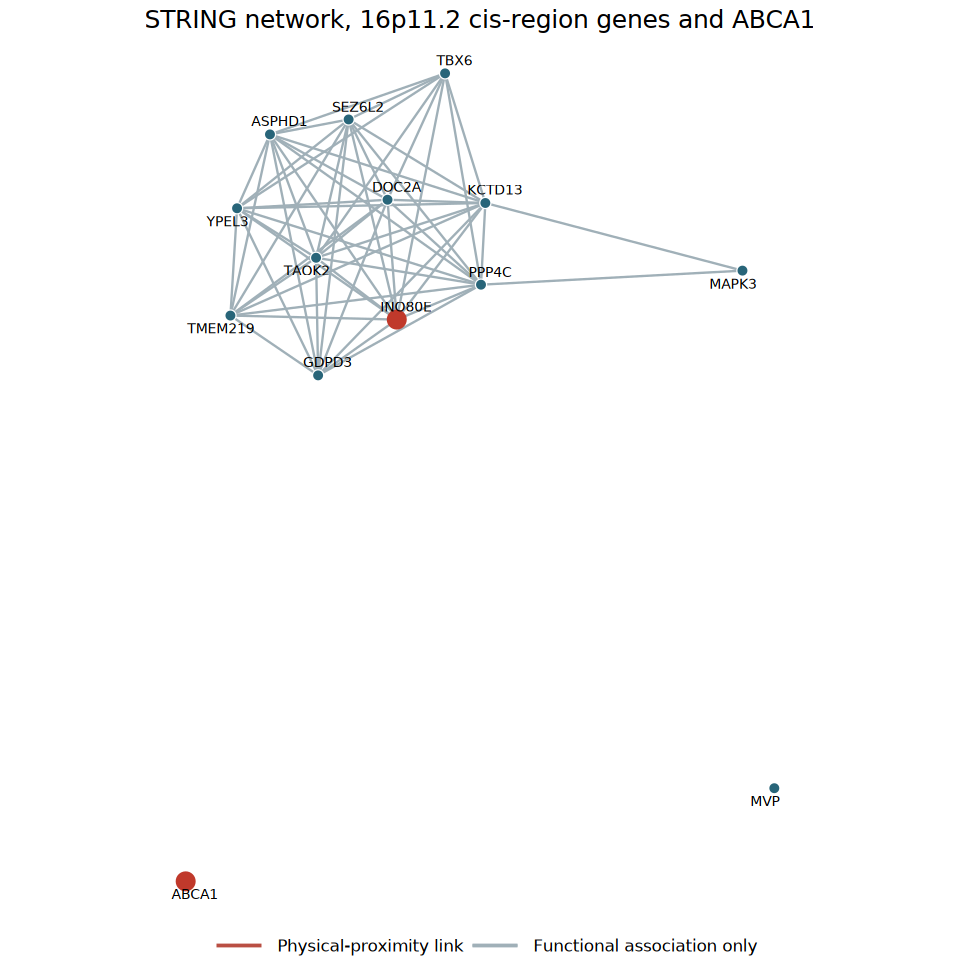

In [2]:
draw_network <- function(ppi, title, label_min_degree = 0, focal_col = "#C0392B") {
  edges <- ppi$edges; nodes <- ppi$nodes
  nodes$lab <- ifelse(nodes$degree >= label_min_degree | nodes$focal, nodes$gene, "")
  ggplot() +
    geom_segment(data = edges[edges$type == "Functional association only", ],
                 aes(x, y, xend = xend, yend = yend, colour = type), linewidth = 0.5) +
    geom_segment(data = edges[edges$type != "Functional association only", ],
                 aes(x, y, xend = xend, yend = yend, colour = type), linewidth = 0.8) +
    geom_point(data = nodes[!nodes$focal, ], aes(x, y), shape = 21, size = 2.6, fill = "#286579",
               colour = "white", stroke = 0.4) +
    geom_point(data = nodes[nodes$focal, ], aes(x, y), size = 4.5, colour = focal_col) +
    geom_text_repel(data = nodes, aes(x, y, label = lab), size = 2.8, fontface = "italic", seed = 1,
                    max.overlaps = Inf, min.segment.length = 0.3, segment.colour = "grey70",
                    segment.size = 0.25) +
    scale_colour_manual(values = c("Physical-proximity link" = "#B94F43",
                                   "Functional association only" = "#A0B0B8"),
                        limits = c("Physical-proximity link", "Functional association only"),
                        drop = FALSE, name = NULL) +
    labs(title = title) +
    coord_fixed() +
    theme_void(base_size = 12) +
    theme(plot.title = element_text(hjust = 0.5), legend.position = "bottom",
          legend.key.width = grid::unit(12, "mm"))
}

ppi$nodes$focal <- ppi$nodes$gene %in% c("INO80E", "ABCA1")
p <- draw_network(ppi, "STRING network, 16p11.2 cis-region genes and ABCA1")
options(repr.plot.width = 8, repr.plot.height = 8)
p